# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,codigo_departamento,codigo_municipio,departamento,municipio,longitud_territorial,latitud_territorial,estado_union,merge_indicador,fuente_analisis,fuente_territorial
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,52,52835,NARIÑO,SAN ANDRÉS DE TUMACO,-78.764073,1.807399,coincide,both,agrosavia.csv,divipola.csv (corte 2024)
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,41,41676,HUILA,SANTA MARÍA,-75.586223,2.939603,coincide,both,agrosavia.csv,divipola.csv (corte 2024)
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,05,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,agrosavia.csv,divipola.csv (corte 2024)
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,05,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,agrosavia.csv,divipola.csv (corte 2024)
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,05,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,agrosavia.csv,divipola.csv (corte 2024)


(92738, 54)
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable                         object
Magnesio intercambiable           

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 54)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ Secuencia ┆ Fecha de  ┆ Departame ┆ Municipio ┆ … ┆ estado_un ┆ merge_ind ┆ fuente_an ┆ fuente_t │
│ l         ┆ Análisis  ┆ nto       ┆ ---       ┆   ┆ ion       ┆ icador    ┆ alisis    ┆ erritori │
│ ---       ┆ ---       ┆ ---       ┆ str       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ al       │
│ str       ┆ str       ┆ str       ┆           ┆   ┆ str       ┆ str       ┆ str       ┆ ---      │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ str      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 1         ┆ 7/01/2014 ┆ NARIÑO    ┆ SAN       ┆ … ┆ coincide  ┆ both      ┆ agrosavia ┆ divipola │
│           ┆           ┆           ┆ ANDRÉS DE ┆   ┆           ┆           ┆ .csv      ┆ .csv     │
│           ┆           ┆           ┆ TUMACO    ┆   ┆           ┆           

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [5]:
# Desarrollo
filas_entrada = datos_pd.shape[0]
assert datos_pl.shape[0] == filas_entrada == 92738
print("Filas de entrada:", filas_entrada)
# Prepara la proyección común e implementa la consulta en ambos motores.

columnas = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]

proy_pd = datos_pd[columnas].copy()
proy_pl = datos_pl.select(columnas)

print(proy_pd.shape, proy_pl.shape)
print(proy_pd.dtypes)
print(proy_pl.schema)
assert len(proy_pd) == proy_pl.height == filas_entrada

Filas de entrada: 92738
(92738, 6) (92738, 6)
id_fila                         Int64
anio                            Int64
codigo_departamento    string[python]
codigo_municipio       string[python]
ph                            float64
ph_valido                        bool
dtype: object
Schema({'id_fila': Int64, 'anio': Int64, 'codigo_departamento': String, 'codigo_municipio': String, 'ph': Float64, 'ph_valido': Boolean})


**Contrato común**

| Campo | pandas | Polars | Nulos |
|---|---|---|---|
| `id_fila` | Int64 | Int64 | No admite |
| `anio` | Int64 | Int64 | `<NA>` / `null` si no hay fecha |
| `codigo_departamento` | string | String | `<NA>` / `null` si no se asocia |
| `codigo_municipio` | string | String | `<NA>` / `null` si no se asocia |
| `ph` | float64 | Float64 | `NaN`/`<NA>` / `null` si no hay pH |
| `ph_valido` | bool | Boolean | No admite |

**Nulos en CSV:** se escriben como celda vacía (el valor por defecto de `to_csv` y `write_csv`).
**Códigos con ceros iniciales:** al leer el CSV se declaran como texto (`dtype=str` en pandas; `schema_overrides={"codigo_departamento": pl.String, "codigo_municipio": pl.String}` en Polars), para que `05001` no pase a `5001`. En pandas hay que añadir `keep_default_na=False` solo si se quiere distinguir vacío de nulo; aquí un vacío se lee como nulo.

In [7]:
print(proy_pd["anio"].value_counts().sort_index())
print(proy_pd.groupby("codigo_departamento", dropna=False).size().sort_values(ascending=False).head(8))

anio_elegido = 2024
#Departamento del Meta
depto_elegido = "50"

sel_pd = proy_pd.loc[
    proy_pd["anio"].eq(anio_elegido) & proy_pd["codigo_departamento"].eq(depto_elegido)
].copy()
sel_pd["ph_para_media"] = sel_pd["ph"].where(sel_pd["ph_valido"])

res_pd = (
    sel_pd
    .groupby("codigo_municipio", dropna=False)
    .agg(
        total_analisis=("id_fila", "size"),
        ph_validos=("ph_valido", "sum"),
        ph_media=("ph_para_media", "mean"),
    )
    .reset_index()
)
display(res_pd.head())
print(res_pd.shape, "| análisis:", res_pd["total_analisis"].sum())

res_pl = (
    proy_pl
    .filter((pl.col("anio") == anio_elegido) & (pl.col("codigo_departamento") == depto_elegido))
    .with_columns(
        pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media")
    )
    .group_by("codigo_municipio")
    .agg(
        pl.len().alias("total_analisis"),
        pl.col("ph_valido").sum().alias("ph_validos"),
        pl.col("ph_para_media").mean().alias("ph_media"),
    )
    .sort("codigo_municipio")
)
print(res_pl.head())
print(res_pl.shape, "| análisis:", res_pl["total_analisis"].sum())

nulos_pl = proy_pl.group_by("codigo_municipio").agg(pl.len().alias("n")).filter(pl.col("codigo_municipio").is_null())
nulos_pd = proy_pd.groupby("codigo_municipio", dropna=False).size().loc[lambda s: s.index.isna()]
print("Polars, grupo nulo:", nulos_pl["n"].to_list(), "| pandas, grupo nulo:", nulos_pd.to_list())

a = res_pd.sort_values("codigo_municipio").reset_index(drop=True)
b = res_pl.sort("codigo_municipio").to_pandas().reset_index(drop=True)

assert a["codigo_municipio"].tolist() == b["codigo_municipio"].tolist()
assert (a["total_analisis"].astype("int64") == b["total_analisis"].astype("int64")).all()
assert (a["ph_validos"].astype("int64") == b["ph_validos"].astype("int64")).all()

pd.testing.assert_series_equal(
    a["ph_media"].astype("float64"), b["ph_media"].astype("float64"),
    check_names=False, atol=0.000001, rtol=0,
)
assert a["ph_media"].isna().equals(b["ph_media"].isna())

anio
2014    10886
2015    13228
2016    14539
2017     7655
2018     4208
2019     5983
2020     5048
2021     7229
2022     9784
2023     7847
2024     3646
2025     2685
Name: count, dtype: Int64
codigo_departamento
25    14012
76     9243
50     8729
05     7907
52     5957
15     5265
68     4689
54     3900
dtype: int64


,codigo_municipio,total_analisis,ph_validos,ph_media
0,50001,27,27,5.166667
1,50006,22,22,4.736364
2,50110,1,1,5.140000
3,50150,4,4,4.917500
4,50226,1,1,4.980000


(26, 4) | análisis: 296
shape: (5, 4)
┌──────────────────┬────────────────┬────────────┬──────────┐
│ codigo_municipio ┆ total_analisis ┆ ph_validos ┆ ph_media │
│ ---              ┆ ---            ┆ ---        ┆ ---      │
│ str              ┆ u32            ┆ u32        ┆ f64      │
╞══════════════════╪════════════════╪════════════╪══════════╡
│ 50001            ┆ 27             ┆ 27         ┆ 5.166667 │
│ 50006            ┆ 22             ┆ 22         ┆ 4.736364 │
│ 50110            ┆ 1              ┆ 1          ┆ 5.14     │
│ 50150            ┆ 4              ┆ 4          ┆ 4.9175   │
│ 50226            ┆ 1              ┆ 1          ┆ 4.98     │
└──────────────────┴────────────────┴────────────┴──────────┘
(26, 4) | análisis: 296
Polars, grupo nulo: [177] | pandas, grupo nulo: [177]


**Interpretación:**

Se proyectaron en pandas y Polars las mismas seis columnas (`id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph`, `ph_valido`) con tipos equivalentes, conservando las **92.738** filas. Se eligieron el año **2024** y el departamento **50 (Meta)**, y se agrupó por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. El pH no válido se excluyó de la media con `where` en pandas y `when/then/otherwise` en Polars, sin reemplazarlo por cero.

**Resultado.** Ambos motores devuelven **26 municipios** y **296 análisis**. Tras ordenar por `codigo_municipio`, las claves, los totales y los pH válidos coinciden exactamente, y las medias coinciden con tolerancia absoluta 0,000001 y relativa cero. Los valores ausentes de la media caen en las mismas posiciones en ambos.

**Nulos.** En pandas se usó `groupby(..., dropna=False)`. En Polars, `group_by` conserva por defecto las claves nulas como un grupo propio. Al agrupar toda la tabla por `codigo_municipio`, los dos motores devuelven un grupo nulo de **177** análisis. Ese grupo no aparece en la selección de Meta, porque esos análisis no tienen departamento.

**Límites.**
- La comparación cubre un solo año y un departamento.
- Los tipos de conteo difieren (`u32` en Polars, `int64` en pandas) y se igualaron antes de comparar.
- La media del pH describe los análisis disponibles, no el suelo completo del municipio.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [9]:
# Desarrollo
from datetime import datetime

proyeccion_pd = proy_pd.copy()

EJECUCION = Path(OUT) / ("ejecucion_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
EJECUCION.mkdir(parents=True, exist_ok=False)
print("Ejecución:", EJECUCION)
print(proyeccion_pd.shape)

# Escribe las cuatro representaciones y presenta su inventario de particiones.
ruta_csv = EJECUCION / "proyeccion.csv"
ruta_parquet = EJECUCION / "proyeccion.parquet"

proyeccion_pd.to_csv(ruta_csv, index=False)
proyeccion_pd.to_parquet(ruta_parquet, engine="pyarrow", compression="snappy", index=False)

print("CSV:", ruta_csv.stat().st_size, "bytes")
print("Parquet:", ruta_parquet.stat().st_size, "bytes")

carpeta_anio = EJECUCION / "por_anio"
carpeta_anio.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta_anio / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(EJECUCION / "inventario_anio.csv", index=False)
display(inventario_anio)

carpeta_anio_dep = EJECUCION / "por_anio_departamento"
carpeta_anio_dep.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, ((anio, depto), grupo) in enumerate(
    proyeccion_pd.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)
):
    archivo = carpeta_anio_dep / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "codigo_departamento": depto,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio_dep = pd.DataFrame(inventario)
inventario_anio_dep.to_csv(EJECUCION / "inventario_anio_departamento.csv", index=False)
display(inventario_anio_dep.head(10))
print("Partes por año:", len(inventario_anio), "| por año y departamento:", len(inventario_anio_dep))

inv_anio = pd.read_csv(
    EJECUCION / "inventario_anio.csv",
    dtype={"anio": "Int64", "archivo": "string"},
)
inv_anio_dep = pd.read_csv(
    EJECUCION / "inventario_anio_departamento.csv",
    dtype={"anio": "Int64", "codigo_departamento": "string", "archivo": "string"},
)
print(inv_anio.dtypes)
print(inv_anio_dep.dtypes)
print("Departamento ausente en inventario:", inv_anio_dep["codigo_departamento"].isna().sum(), "grupo(s)")

def releer(inventario):
    partes = [pd.read_parquet(EJECUCION / ruta, engine="pyarrow") for ruta in inventario["archivo"]]
    return pd.concat(partes, ignore_index=True)

ref = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)

for nombre, inv in [("por año", inv_anio), ("por año y departamento", inv_anio_dep)]:
    rel = releer(inv).sort_values("id_fila").reset_index(drop=True)
    assert len(rel) == len(ref) == filas_entrada
    assert rel["id_fila"].is_unique
    assert rel["id_fila"].equals(ref["id_fila"])
    pd.testing.assert_frame_equal(ref, rel)
    assert inv["filas"].sum() == filas_entrada
    print(nombre, "- filas, IDs únicos y contenido idénticos")

rel_unico = pd.read_parquet(ruta_parquet, engine="pyarrow").sort_values("id_fila").reset_index(drop=True)
pd.testing.assert_frame_equal(ref, rel_unico)

comparacion = pd.DataFrame({
    "diseño": ["Parquet único", "Por año", "Por año y departamento"],
    "archivos": [1, len(inv_anio), len(inv_anio_dep)],
    "bytes_totales": [
        ruta_parquet.stat().st_size,
        inv_anio["bytes"].sum(),
        inv_anio_dep["bytes"].sum(),
    ],
    "filas_por_archivo_min": [len(proyeccion_pd), inv_anio["filas"].min(), inv_anio_dep["filas"].min()],
    "filas_por_archivo_max": [len(proyeccion_pd), inv_anio["filas"].max(), inv_anio_dep["filas"].max()],
})
display(comparacion)
print("Archivos con menos de 100 filas (por año y depto.):", (inv_anio_dep["filas"] < 100).sum())

Ejecución: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261016_131838
(92738, 6)
CSV: 2763055 bytes
Parquet: 834028 bytes


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96458
1,2015,por_anio/parte-0001.parquet,13228,116250
2,2016,por_anio/parte-0002.parquet,14539,130611
3,2017,por_anio/parte-0003.parquet,7655,72225
4,2018,por_anio/parte-0004.parquet,4208,42054
5,2019,por_anio/parte-0005.parquet,5983,57457
6,2020,por_anio/parte-0006.parquet,5048,50637
7,2021,por_anio/parte-0007.parquet,7229,68627
8,2022,por_anio/parte-0008.parquet,9784,88474
9,2023,por_anio/parte-0009.parquet,7847,71357


,anio,codigo_departamento,archivo,filas,bytes
0,2014,05,por_anio_departamento/parte-0000.parquet,517,8336
1,2014,08,por_anio_departamento/parte-0001.parquet,16,4020
2,2014,11,por_anio_departamento/parte-0002.parquet,24,4041
3,2014,13,por_anio_departamento/parte-0003.parquet,192,5471
4,2014,15,por_anio_departamento/parte-0004.parquet,484,8128
5,2014,17,por_anio_departamento/parte-0005.parquet,14,3964
6,2014,18,por_anio_departamento/parte-0006.parquet,1,3780
7,2014,19,por_anio_departamento/parte-0007.parquet,98,4853
8,2014,20,por_anio_departamento/parte-0008.parquet,182,5692
9,2014,23,por_anio_departamento/parte-0009.parquet,370,6936


Partes por año: 12 | por año y departamento: 372
anio                Int64
archivo    string[python]
filas               int64
bytes               int64
dtype: object
anio                            Int64
codigo_departamento    string[python]
archivo                string[python]
filas                           int64
bytes                           int64
dtype: object
Departamento ausente en inventario: 11 grupo(s)
por año - filas, IDs únicos y contenido idénticos
por año y departamento - filas, IDs únicos y contenido idénticos


,diseño,archivos,bytes_totales,filas_por_archivo_min,filas_por_archivo_max
0,Parquet único,1,834028,92738,92738
1,Por año,12,862349,2685,14539
2,Por año y departamento,372,2245289,1,4742


Archivos con menos de 100 filas (por año y depto.): 183


**Interpretación:**

Se escribió la misma proyección en cuatro formas: CSV único (2.763.055 bytes), Parquet único (834.028 bytes), Parquet por año (12 archivos) y Parquet por año y departamento (372 archivos). Todos los Parquet usan Snappy e `index=False`, y cada construcción se escribió en una carpeta nueva de `OUT`. El número de `parte-XXXX` es solo secuencial; el año y el departamento están en el inventario, no en el nombre.

**Nulos y claves.** Con `groupby(..., dropna=False)`, las filas sin departamento formaron **11 grupos propios** y no desaparecieron. Al releer los inventarios con `anio` como `Int64` y el código como `string`, los ceros iniciales y las ausencias se conservaron.

**Control.** Se releyeron todos los archivos por ruta, se concatenaron con `ignore_index=True` y se compararon con la proyección ordenada por `id_fila`. Las 92.738 filas, los `id_fila` únicos y el contenido son idénticos en ambos diseños, y los inventarios suman las 92.738 filas.

**Comparación de diseños.**

| Diseño | Archivos | Bytes | Filas por archivo |
|---|---|---|---|
| Parquet único | 1 | 834.028 | 92.738 |
| Por año | 12 | 862.349 | 2.685 a 14.539 |
| Por año y departamento | 372 | 2.245.289 | 1 a 4.742 |

Dividir por año aumenta el tamaño un 3,4 %. Dividir por año y departamento lo multiplica por cerca de 2,7 y deja **183 archivos con menos de 100 filas**, uno de ellos con una sola fila. Cada archivo paga metadatos fijos, así que muchas particiones pequeñas pierden compresión.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [11]:
# Desarrollo
from datetime import datetime
import polars.testing

with open("/proc/meminfo") as f:
    meminfo = dict(l.split(":", 1) for l in f)
ram_disp_gb = int(meminfo["MemAvailable"].split()[0]) / 1024 / 1024

print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| Polars:", pl.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
print("RAM disponible (GB):", round(ram_disp_gb, 1))
print("Archivos leídos:", ruta_csv, ruta_parquet)

EJEC3 = Path(OUT) / ("medicion_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
EJEC3.mkdir(parents=True, exist_ok=False)
print("Escrituras en:", EJEC3)

tipos_pd = {"id_fila": "Int64", "anio": "Int64", "codigo_departamento": "string",
            "codigo_municipio": "string", "ph": "float64", "ph_valido": "bool"}
tipos_pl = {"id_fila": pl.Int64, "anio": pl.Int64, "codigo_departamento": pl.String,
            "codigo_municipio": pl.String, "ph": pl.Float64, "ph_valido": pl.Boolean}
corridas = ["inicial", 1, 2, 3, 4, 5]

# Mide con llamadas directas a read_csv/read_parquet y to_csv/to_parquet o write_csv/write_parquet.
lecturas = []
leidos = {}
for i, corrida in enumerate(corridas):
    orden = ["pandas", "polars"] if i % 2 == 0 else ["polars", "pandas"]
    for motor in orden:
        for formato in ["csv", "parquet"]:
            if motor == "pandas" and formato == "csv":
                t0 = time.perf_counter()
                res = pd.read_csv(ruta_csv, dtype=tipos_pd)
                t1 = time.perf_counter()
            elif motor == "pandas":
                t0 = time.perf_counter()
                res = pd.read_parquet(ruta_parquet, engine="pyarrow", columns=columnas).astype(tipos_pd)
                t1 = time.perf_counter()
            elif formato == "csv":
                t0 = time.perf_counter()
                res = pl.read_csv(ruta_csv, schema_overrides=tipos_pl)
                t1 = time.perf_counter()
            else:
                t0 = time.perf_counter()
                res = pl.read_parquet(ruta_parquet, columns=columnas).cast(tipos_pl)
                t1 = time.perf_counter()
            lecturas.append({"corrida": corrida, "motor": motor, "formato": formato, "segundos": t1 - t0})
            leidos[(motor, formato)] = res

ref_pd = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
ref_pl = proy_pl.sort("id_fila")

for (motor, formato), res in leidos.items():
    if motor == "pandas":
        pd.testing.assert_frame_equal(res.sort_values("id_fila").reset_index(drop=True), ref_pd)
    else:
        pl.testing.assert_frame_equal(res.sort("id_fila"), ref_pl)
    print( motor, formato, res.shape)

escrituras = []
escritos = []
for i, corrida in enumerate(corridas):
    orden = ["pandas", "polars"] if i % 2 == 0 else ["polars", "pandas"]
    carpeta = EJEC3 / f"corrida_{corrida}"
    carpeta.mkdir(parents=True, exist_ok=False)
    for motor in orden:
        for formato in ["csv", "parquet"]:
            destino = carpeta / f"{motor}.{formato}"
            if motor == "pandas" and formato == "csv":
                t0 = time.perf_counter()
                proyeccion_pd.to_csv(destino, index=False, sep=",", na_rep="")
                t1 = time.perf_counter()
            elif motor == "pandas":
                t0 = time.perf_counter()
                proyeccion_pd.to_parquet(destino, engine="pyarrow", compression="snappy", index=False)
                t1 = time.perf_counter()
            elif formato == "csv":
                t0 = time.perf_counter()
                proy_pl.write_csv(destino, separator=",", null_value="")
                t1 = time.perf_counter()
            else:
                t0 = time.perf_counter()
                proy_pl.write_parquet(destino, compression="snappy")
                t1 = time.perf_counter()
            escrituras.append({"corrida": corrida, "motor": motor, "formato": formato, "segundos": t1 - t0})
            escritos.append((motor, formato, destino))

for motor, formato, destino in escritos:
    if formato == "csv":
        rel = pd.read_csv(destino, dtype=tipos_pd)
    else:
        rel = pd.read_parquet(destino, engine="pyarrow").astype(tipos_pd)
    pd.testing.assert_frame_equal(rel.sort_values("id_fila").reset_index(drop=True), ref_pd)
print(len(escritos), "archivos releídos y equivalentes")
print(pd.Series({f"{m}.{f}": d.stat().st_size for m, f, d in escritos[:4]}))

tiempos = pd.concat([
    pd.DataFrame(lecturas).assign(operacion="lectura"),
    pd.DataFrame(escrituras).assign(operacion="escritura"),
])
display(tiempos.loc[tiempos["corrida"].eq("inicial")])

rep = tiempos.loc[tiempos["corrida"].ne("inicial")]
display(rep.pivot_table(index=["operacion", "formato"], columns="motor",
                        values="segundos", aggfunc=["median", "min", "max"]))
display(rep.pivot(index="corrida", columns=["operacion", "motor", "formato"], values="segundos"))

Python: 3.12.15 | pandas: 2.2.3 | Polars: 1.35.2
CPU: x86_64 | núcleos: 24
RAM disponible (GB): 4.5
Archivos leídos: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261016_131838/proyeccion.csv /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261016_131838/proyeccion.parquet
Escrituras en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/medicion_20261016_132750
pandas csv (92738, 6)
pandas parquet (92738, 6)
polars csv (92738, 6)
polars parquet (92738, 6)
24 archivos releídos y equivalentes
pandas.csv        2763055
pandas.parquet     834028
polars.csv        2763055
polars.parquet     764912
dtype: int64


,corrida,motor,formato,segundos,operacion
0,inicial,pandas,csv,0.113988,lectura
1,inicial,pandas,parquet,0.028075,lectura
2,inicial,polars,csv,0.031041,lectura
3,inicial,polars,parquet,0.021162,lectura
0,inicial,pandas,csv,0.202007,escritura
1,inicial,pandas,parquet,0.071079,escritura
2,inicial,polars,csv,0.051095,escritura
3,inicial,polars,parquet,0.031350,escritura


median                 min                 max          
motor                pandas    polars    pandas    polars    pandas    polars
operacion formato                                                            
escritura csv      0.628917  0.148442  0.214802  0.046065  0.746509  0.191659
          parquet  0.100420  0.057050  0.047911  0.024633  0.109035  0.072430
lectura   csv      0.086470  0.031189  0.082723  0.029821  0.097399  0.042159
          parquet  0.021338  0.019848  0.020435  0.018060  0.025045  0.024910

operacion   lectura                               escritura            \
motor        polars              pandas              polars             
formato         csv   parquet       csv   parquet       csv   parquet   
corrida                                                                 
1          0.031634  0.022188  0.097399  0.025045  0.046065  0.024633   
2          0.042159  0.024910  0.084644  0.021338  0.144130  0.054473   
3          0.029821  0.019848  0.082723  0.020667  0.148442  0.057050   
4          0.031189  0.018060  0.087035  0.021513  0.191659  0.070591   
5          0.031167  0.019335  0.086470  0.020435  0.184374  0.072430   

operacion                      
motor        pandas            
formato         csv   parquet  
corrida                        
1          0.214802  0.047911  
2          0.399973  0.107074  
3          0.628917  0.109035  
4          0.746509  0.100420  
5          0.663045  0.094846

**Interpretación:**

Se midieron lectura y escritura de la misma proyección en CSV y Parquet con pandas y Polars, usando `time.perf_counter()` justo antes y después de cada llamada. Hubo una ejecución inicial separada y cinco repeticiones que alternan el orden de motores; cada repetición escribió en una carpeta nueva. Las conversiones del contrato están dentro de las celdas de lectura; la validación, la impresión y el inventario quedaron fuera del intervalo. Todas las lecturas y los 24 archivos escritos se releyeron fuera de la medición y son equivalentes a la proyección ordenada por `id_fila`.

**Entorno.** Python 3.12.15, pandas 2.2.3, Polars 1.35.2, CPU x86_64 con 24 núcleos, 4,5 GB de RAM disponible, WSL2. Los archivos se leen y escriben en `kit/salidas/soluciones/PD05/`, dentro de `/mnt/c/...` (disco de Windows).

**Resultados (mediana de cinco repeticiones, en segundos).**

| Operación | Formato | pandas | Polars |
|---|---|---|---|
| Lectura | CSV | 0,086 | 0,031 |
| Lectura | Parquet | 0,021 | 0,020 |
| Escritura | CSV | 0,629 | 0,148 |
| Escritura | Parquet | 0,100 | 0,057 |

En CSV, Polars fue más rápido que pandas en todas las repeticiones, tanto en lectura como en escritura. En lectura de Parquet la diferencia es de milésimas de segundo y los rangos se traslapan, así que no hay base para declarar un ganador. Para ambos motores, leer Parquet fue más rápido que leer CSV.

**Opciones que no se pudieron igualar.** Pandas escribe los booleanos como `True/False` y Polars como `true/false`; ambos se releyeron con el mismo contrato. Los Parquet difieren en bytes aunque ambos usan Snappy, porque cada motor usa su propio escritor y metadatos; por eso la equivalencia se verificó por relectura y no por tamaño. El CSV pesa lo mismo en ambos (2.763.055 bytes).

**Límites.**
- La escritura de CSV con pandas varió entre 0,21 y 0,75 s en las repeticiones, por lo que su mediana es poco estable. Los archivos están en `/mnt/c`, y esa variabilidad pudo influir, pero no se aisló la causa.
- Son cinco repeticiones sobre 92.738 filas en una sola máquina. Los resultados no se extrapolan a otros tamaños ni equipos.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [12]:
# Desarrollo
tipos_inv = {"anio": "Int64", "codigo_departamento": "string", "archivo": "string"}
archivo_inv = {
    "por_anio": "inventario_anio.csv",
    "por_anio_departamento": "inventario_anio_departamento.csv",
}
variantes = ["unico", "por_anio", "por_anio_departamento"]

vacio_pd = pd.DataFrame({c: pd.Series(dtype=t) for c, t in tipos_pd.items()})
vacio_pl = pl.DataFrame(schema=tipos_pl)

for variante in ["por_anio", "por_anio_departamento"]:
    inv = pd.read_csv(EJECUCION / archivo_inv[variante], dtype=tipos_inv)
    if variante == "por_anio":
        sel = inv.loc[inv["anio"].eq(anio_elegido)]
    else:
        sel = inv.loc[inv["anio"].eq(anio_elegido) & inv["codigo_departamento"].eq(depto_elegido)]
    print(variante, "-> archivos candidatos:", len(sel), "| filas:", sel["filas"].sum())

mem = []
res_mem = {}
for rep in range(1, 6):
    orden = ["pandas", "polars"] if rep % 2 == 1 else ["polars", "pandas"]
    for motor in orden:
        if motor == "pandas":
            t0 = time.perf_counter()
            sel = proyeccion_pd.loc[
                proyeccion_pd["anio"].eq(anio_elegido) & proyeccion_pd["codigo_departamento"].eq(depto_elegido)
            ]
            sel = sel.assign(ph_para_media=sel["ph"].where(sel["ph_valido"]))
            res = (
                sel.groupby("codigo_municipio", dropna=False)
                .agg(total_analisis=("id_fila", "size"),
                     ph_validos=("ph_valido", "sum"),
                     ph_media=("ph_para_media", "mean"))
                .reset_index()
            )
            t1 = time.perf_counter()
        else:
            t0 = time.perf_counter()
            res = (
                proy_pl
                .filter((pl.col("anio") == anio_elegido) & (pl.col("codigo_departamento") == depto_elegido))
                .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                .group_by("codigo_municipio")
                .agg(pl.len().alias("total_analisis"),
                     pl.col("ph_valido").sum().alias("ph_validos"),
                     pl.col("ph_para_media").mean().alias("ph_media"))
            )
            t1 = time.perf_counter()
        mem.append({"repeticion": rep, "motor": motor, "segundos": t1 - t0})
        res_mem[motor] = res

disco = []
res_disco = {}
rutas_usadas = {}
for rep in range(1, 6):
    orden = ["pandas", "polars"] if rep % 2 == 1 else ["polars", "pandas"]
    for variante in variantes:
        for motor in orden:
            t0 = time.perf_counter()

            if variante == "unico":
                rutas = [ruta_parquet]
            else:
                inv = pd.read_csv(EJECUCION / archivo_inv[variante], dtype=tipos_inv)
                if variante == "por_anio":
                    sel_inv = inv.loc[inv["anio"].eq(anio_elegido)]
                else:
                    sel_inv = inv.loc[inv["anio"].eq(anio_elegido) & inv["codigo_departamento"].eq(depto_elegido)]
                rutas = [EJECUCION / r for r in sel_inv["archivo"]]

            if motor == "pandas":
                partes_pd = []
                for ruta in rutas:
                    parte_pd = pd.read_parquet(ruta, engine="pyarrow", columns=columnas)
                    partes_pd.append(parte_pd)
                seleccion = pd.concat(partes_pd, ignore_index=True) if partes_pd else vacio_pd.copy()
                sel = seleccion.loc[
                    seleccion["anio"].eq(anio_elegido) & seleccion["codigo_departamento"].eq(depto_elegido)
                ]
                sel = sel.assign(ph_para_media=sel["ph"].where(sel["ph_valido"]))
                res = (
                    sel.groupby("codigo_municipio", dropna=False)
                    .agg(total_analisis=("id_fila", "size"),
                         ph_validos=("ph_valido", "sum"),
                         ph_media=("ph_para_media", "mean"))
                    .reset_index()
                )
            else:
                partes_pl = []
                for ruta in rutas:
                    parte_pl = pl.read_parquet(ruta, columns=columnas)
                    partes_pl.append(parte_pl)
                seleccion = pl.concat(partes_pl) if partes_pl else vacio_pl.clone()
                res = (
                    seleccion
                    .filter((pl.col("anio") == anio_elegido) & (pl.col("codigo_departamento") == depto_elegido))
                    .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                    .group_by("codigo_municipio")
                    .agg(pl.len().alias("total_analisis"),
                         pl.col("ph_valido").sum().alias("ph_validos"),
                         pl.col("ph_para_media").mean().alias("ph_media"))
                )

            t1 = time.perf_counter()
            disco.append({"repeticion": rep, "variante": variante, "motor": motor, "segundos": t1 - t0})
            res_disco[(variante, motor)] = res
            rutas_usadas[(variante, motor)] = [str(r.relative_to(EJECUCION)) for r in rutas]

dif = []
res_dif = {}
for rep in range(1, 6):
    orden = ["eager", "lazy"] if rep % 2 == 1 else ["lazy", "eager"]
    for modo in orden:
        if modo == "eager":
            t0 = time.perf_counter()
            res = (
                pl.read_parquet(ruta_parquet, columns=columnas)
                .filter((pl.col("anio") == anio_elegido) & (pl.col("codigo_departamento") == depto_elegido))
                .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                .group_by("codigo_municipio")
                .agg(pl.len().alias("total_analisis"),
                     pl.col("ph_valido").sum().alias("ph_validos"),
                     pl.col("ph_para_media").mean().alias("ph_media"))
            )
            t1 = time.perf_counter()
        else:
            t0 = time.perf_counter()
            res = (
                pl.scan_parquet(ruta_parquet)
                .select(columnas)
                .filter((pl.col("anio") == anio_elegido) & (pl.col("codigo_departamento") == depto_elegido))
                .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
                .group_by("codigo_municipio")
                .agg(pl.len().alias("total_analisis"),
                     pl.col("ph_valido").sum().alias("ph_validos"),
                     pl.col("ph_para_media").mean().alias("ph_media"))
                .collect()
            )
            t1 = time.perf_counter()
        dif.append({"repeticion": rep, "modo": modo, "segundos": t1 - t0})
        res_dif[modo] = res

plan = (
    pl.scan_parquet(ruta_parquet)
    .select(columnas)
    .filter((pl.col("anio") == anio_elegido) & (pl.col("codigo_departamento") == depto_elegido))
    .with_columns(pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None).alias("ph_para_media"))
    .group_by("codigo_municipio")
    .agg(pl.len().alias("total_analisis"),
         pl.col("ph_valido").sum().alias("ph_validos"),
         pl.col("ph_para_media").mean().alias("ph_media"))
)
print(plan.explain())

ref = res_pd.sort_values("codigo_municipio").reset_index(drop=True)

todos = [("memoria", m, r) for m, r in res_mem.items()]
todos += [("disco_" + v, m, r) for (v, m), r in res_disco.items()]
todos += [("polars_" + modo, "polars", r) for modo, r in res_dif.items()]

for nombre, motor, r in todos:
    b = (r if motor == "pandas" else r.to_pandas()).sort_values("codigo_municipio").reset_index(drop=True)
    assert b["codigo_municipio"].tolist() == ref["codigo_municipio"].tolist()
    assert (b["total_analisis"].astype("int64") == ref["total_analisis"].astype("int64")).all()
    assert (b["ph_validos"].astype("int64") == ref["ph_validos"].astype("int64")).all()
    pd.testing.assert_series_equal(
        b["ph_media"].astype("float64"), ref["ph_media"].astype("float64"),
        check_names=False, atol=0.000001, rtol=0,
    )
print(len(todos), "resultados equivalentes a la referencia")

for v in variantes:
    assert rutas_usadas[(v, "pandas")] == rutas_usadas[(v, "polars")]
    print(v, "->", rutas_usadas[(v, "pandas")])

t_mem = pd.DataFrame(mem)
t_disco = pd.DataFrame(disco)
t_dif = pd.DataFrame(dif)

display(t_mem.groupby("motor")["segundos"].agg(["median", "min", "max"]))
display(t_disco.pivot_table(index="variante", columns="motor", values="segundos",
                            aggfunc=["median", "min", "max"]))
display(t_dif.groupby("modo")["segundos"].agg(["median", "min", "max"]))

display(t_mem.pivot(index="repeticion", columns="motor", values="segundos"))
display(t_disco.pivot(index="repeticion", columns=["variante", "motor"], values="segundos"))
display(t_dif.pivot(index="repeticion", columns="modo", values="segundos"))

por_anio -> archivos candidatos: 1 | filas: 3646
por_anio_departamento -> archivos candidatos: 1 | filas: 296
AGGREGATE[maintain_order: false]
  [len().alias("total_analisis"), col("ph_valido").sum().alias("ph_validos"), col("ph_para_media").mean().alias("ph_media")] BY [col("codigo_municipio")]
  FROM
   WITH_COLUMNS:
   [when(col("ph_valido")).then(col("ph")).otherwise(null.cast(Float64)).alias("ph_para_media")] 
    Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261016_131838/proyeccion.parquet]
    PROJECT 5/6 COLUMNS
    SELECTION: [([(col("anio")) == (2024)]) & ([(col("codigo_departamento")) == ("50")])]
    ESTIMATED ROWS: 92738
10 resultados equivalentes a la referencia
unico -> ['proyeccion.parquet']
por_anio -> ['por_anio/parte-0010.parquet']
por_anio_departamento -> ['por_anio_departamento/parte-0325.parquet']


,median,min,max
motor,,,
pandas,0.007678,0.006696,0.011867
polars,0.007147,0.006409,0.009325


median                 min                 max  \
motor                    pandas    polars    pandas    polars    pandas   
variante                                                                  
por_anio               0.015297  0.028207  0.014356  0.024609  0.017588   
por_anio_departamento  0.013528  0.024239  0.012758  0.023393  0.014307   
unico                  0.024445  0.027157  0.023129  0.025032  0.050836   

                                 
motor                    polars  
variante                         
por_anio               0.036092  
por_anio_departamento  0.026327  
unico                  0.082829

,median,min,max
modo,,,
eager,0.026907,0.022317,0.027984
lazy,0.020978,0.019808,0.036722


motor,pandas,polars
repeticion,,
1,0.011867,0.009325
2,0.008053,0.006409
3,0.006696,0.007477
4,0.007678,0.006591
5,0.006772,0.007147


variante       unico            por_anio           por_anio_departamento  \
motor         pandas    polars    pandas    polars                pandas   
repeticion                                                                 
1           0.050836  0.082829  0.017588  0.036092              0.014307   
2           0.023129  0.028147  0.016348  0.028433              0.012963   
3           0.024445  0.027157  0.015297  0.024609              0.013578   
4           0.024565  0.025032  0.014356  0.028207              0.012758   
5           0.024187  0.026840  0.015108  0.024688              0.013528   

variante              
motor         polars  
repeticion            
1           0.026327  
2           0.024239  
3           0.023393  
4           0.024903  
5           0.023937

modo,eager,lazy
repeticion,,
1,0.027207,0.036722
2,0.025039,0.020978
3,0.022317,0.020573
4,0.027984,0.021592
5,0.026907,0.019808


**Interpretación:**

Se separaron tres experimentos sobre la misma consulta, con cinco repeticiones cada uno, alternando el orden de motores y dejando fuera del intervalo la impresión y las comprobaciones. Los 10 resultados materializados son equivalentes a la referencia (claves y conteos exactos; medias con tolerancia absoluta 0,000001 y relativa cero), y ambos motores usaron exactamente la misma lista de archivos.

**En memoria.** Solo filtro y agregación sobre tablas ya cargadas: mediana de 0,0077 s en pandas y 0,0071 s en Polars. Los rangos se traslapan, así que no hay base para declarar un ganador.

**Desde disco.** El intervalo incluye lectura del inventario CSV, selección de rutas, lectura de partes, `concat`, filtro y agregación. Rutas seleccionadas: `proyeccion.parquet`, `por_anio/parte-0010.parquet` y `por_anio_departamento/parte-0325.parquet`.

| Diseño | pandas (mediana, s) | Polars (mediana, s) |
|---|---|---|
| Archivo único | 0,0244 | 0,0272 |
| Por año | 0,0153 | 0,0282 |
| Por año y departamento | 0,0135 | 0,0242 |

En pandas, leer una sola parte fue más rápido que leer el archivo único. En Polars la diferencia entre diseños es pequeña y no hay una tendencia clara. Con tiempos de milisegundos no se aisló la causa: los costos fijos de abrir archivos y leer el inventario pueden pesar tanto como las filas leídas. El inventario se lee con pandas en ambos motores, por lo que ese tramo es común.

**Consulta diferida.** Sobre el Parquet único, `scan_parquet` con `collect()` tuvo mediana de 0,0210 s y `read_parquet` eager de 0,0269 s. La ventaja aparece en cuatro de cinco repeticiones; la primera de lazy fue la más lenta. `explain()` muestra que la selección de columnas y el filtro se aplican dentro del nodo de lectura del Parquet, lo que es coherente con esa ventaja, aunque no se midió su efecto por separado. En ambos modos el intervalo cubre desde la lectura hasta el resultado, así que no se compara construir un plan con ejecutarlo.

**Límites.**
- No se controló la caché del sistema: las lecturas no se describen como frías, y la primera repetición del archivo único pudo verse afectada.
- Los bytes de los archivos seleccionados no son bytes físicos leídos.
- Dividir archivos no implica procesamiento paralelo: aquí cada parte se lee en un bucle secuencial, y el beneficio, cuando aparece, viene de leer menos datos.
- Son cinco repeticiones sobre 92.738 filas en una sola máquina (WSL2, archivos en `/mnt/c`). Los resultados no se extrapolan a otros tamaños ni equipos.

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [13]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,codigo_municipio,total_analisis,ph_validos,ph_media,anio,area_intersectada_ha,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,05004,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,05021,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 18) EPSG:4326


['codigo_municipio', 'geometry']
(1122, 2) EPSG:4326
Geometrías: 1122 | vacías: 0
Código único: True
Cinco cifras: True
pandas (26, 4) | código único: True | análisis: 296
polars (26, 4) | código único: True | análisis: 296
pandas | polígonos: 1122 | con resultado: 26 | sin resultado: 1096 | resultados sin geometría: 0
polars | polígonos: 1122 | con resultado: 26 | sin resultado: 1096 | resultados sin geometría: 0


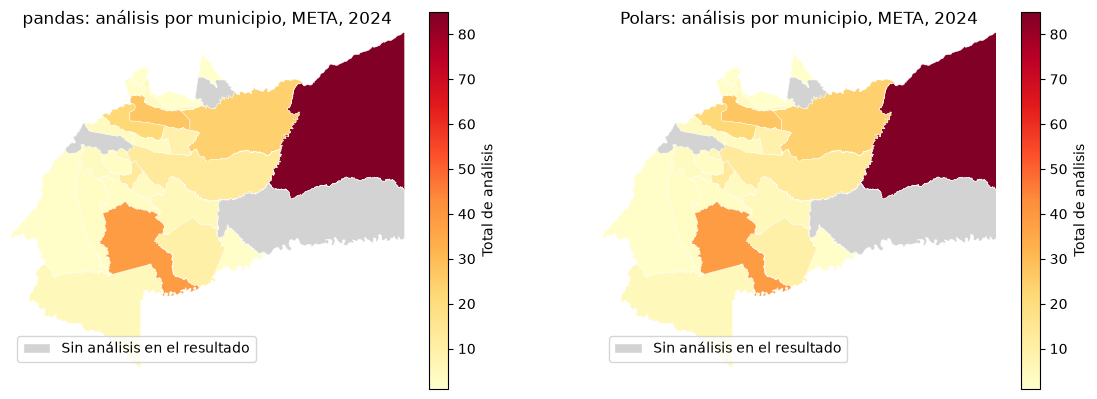

In [14]:
# Desarrollo
municipios_geo = geometrias[["codigo_municipio", "geometry"]].copy()

print(municipios_geo.columns.tolist())
print(municipios_geo.shape, municipios_geo.crs)
print("Geometrías:", municipios_geo.geometry.notna().sum(), "| vacías:", municipios_geo.geometry.is_empty.sum())
print("Código único:", municipios_geo["codigo_municipio"].is_unique)
print("Cinco cifras:", municipios_geo["codigo_municipio"].str.fullmatch(r"[0-9]{5}").all())

res_pd_mapa = res_mem["pandas"].copy()
res_pl_mapa = res_mem["polars"].to_pandas()   # después de medir

for nombre, r in [("pandas", res_pd_mapa), ("polars", res_pl_mapa)]:
    r["codigo_municipio"] = r["codigo_municipio"].astype("string")
    print(nombre, r.shape, "| código único:", r["codigo_municipio"].is_unique, "| análisis:", r["total_analisis"].sum())

a = res_pd_mapa.sort_values("codigo_municipio").reset_index(drop=True)
b = res_pl_mapa.sort_values("codigo_municipio").reset_index(drop=True)

assert a["codigo_municipio"].tolist() == b["codigo_municipio"].tolist()
assert (a["total_analisis"].astype("int64") == b["total_analisis"].astype("int64")).all()
assert (a["ph_validos"].astype("int64") == b["ph_validos"].astype("int64")).all()
pd.testing.assert_series_equal(
    a["ph_media"].astype("float64"), b["ph_media"].astype("float64"),
    check_names=False, atol=0.000001, rtol=0,
)

# Une ambos resultados a las mismas geometrías y comprueba tablas y mapas.
mapa_pd = municipios_geo.merge(res_pd_mapa, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)
mapa_pl = municipios_geo.merge(res_pl_mapa, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)

for nombre, m, r in [("pandas", mapa_pd, res_pd_mapa), ("polars", mapa_pl, res_pl_mapa)]:
    sin_geom = r.loc[~r["codigo_municipio"].isin(municipios_geo["codigo_municipio"])]
    sin_resultado = m["_merge"].eq("left_only").sum()
    print(nombre, "| polígonos:", len(m), "| con resultado:", m["_merge"].eq("both").sum(),
          "| sin resultado:", sin_resultado, "| resultados sin geometría:", len(sin_geom))
    assert len(m) == len(municipios_geo)

from matplotlib.patches import Patch

depto_nombre = "META"
vmin = min(mapa_pd["total_analisis"].min(), mapa_pl["total_analisis"].min())
vmax = max(mapa_pd["total_analisis"].max(), mapa_pl["total_analisis"].max())

meta_pd = mapa_pd.loc[mapa_pd["codigo_municipio"].str.startswith(depto_elegido)]
meta_pl = mapa_pl.loc[mapa_pl["codigo_municipio"].str.startswith(depto_elegido)]
minx, miny, maxx, maxy = meta_pd.total_bounds

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, datos, motor in [(axes[0], meta_pd, "pandas"), (axes[1], meta_pl, "Polars")]:
    datos.plot(
        column="total_analisis", cmap="YlOrRd", vmin=vmin, vmax=vmax,
        legend=True, legend_kwds={"label": "Total de análisis", "shrink": 0.7},
        missing_kwds={"color": "lightgrey", "edgecolor": "white"},
        edgecolor="white", linewidth=0.3, ax=ax,
    )
    ax.set_xlim(minx, maxx)
    ax.set_ylim(miny, maxy)
    ax.set_title(f"{motor}: análisis por municipio, {depto_nombre}, {anio_elegido}")
    ax.set_axis_off()
    ax.legend(handles=[Patch(facecolor="lightgrey", edgecolor="white", label="Sin análisis en el resultado")],
              loc="lower left")

plt.savefig(OUT + "/comparacion_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación:**

Se leyó la capa `municipios` del GeoPackage de PD04: **1.122** geometrías en EPSG:4326, sin geometrías vacías. Se conservaron solo `codigo_municipio` y `geometry`, para no reutilizar los indicadores del año anterior.

**Comprobación numérica.** El resultado de Polars se convirtió con `.to_pandas()` después de medir. Antes de mapear, pandas y Polars coinciden en claves, conteos y pH válidos y en medias: **26 municipios y 296 análisis** en ambos.

**Uniones.** Cada resultado se unió por separado a los polígonos con `how="left"` y `validate="one_to_one"`. En ambos casos se conservaron los **1.122** polígonos: **26** con resultado y **1.096** sin resultado, y **0** resultados sin geometría.

**Mapas.** `comparacion_mapas.png` muestra el departamento 50 (Meta) en 2024, un mapa por motor, con la misma extensión, columna (`total_analisis`), límites de color, leyenda y color gris para los municipios sin resultado. Los dos mapas son visualmente iguales, y eso es consistente con la igualdad numérica ya comprobada.

**Límites.**
- Un mapa igual no sustituye la comparación de valores: la igualdad se verificó con las claves, los conteos y las medias, no con la imagen.
- Las geometrías no participaron en el benchmark tabular. La unión y el dibujo son trabajo de GeoPandas, fuera de los tiempos medidos.
- La media del pH describe los análisis disponibles, y con pocos análisis por municipio es poco estable.

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [17]:
# Desarrollo
EJECUCION2 = Path(OUT) / ("ejecucion_" + datetime.now().strftime("%Y%m%d_%H%M%S") + "_b")
EJECUCION2.mkdir(parents=True, exist_ok=False)

proyeccion_pd.to_csv(EJECUCION2 / "proyeccion.csv", index=False)
proyeccion_pd.to_parquet(EJECUCION2 / "proyeccion.parquet", engine="pyarrow", compression="snappy", index=False)

inv2 = {}
for nombre, claves in [("por_anio", ["anio"]), ("por_anio_departamento", ["anio", "codigo_departamento"])]:
    carpeta = EJECUCION2 / nombre
    carpeta.mkdir(parents=True, exist_ok=False)
    filas_inv = []
    for numero, (clave, grupo) in enumerate(proyeccion_pd.groupby(claves, dropna=False, sort=True)):
        clave = clave if isinstance(clave, tuple) else (clave,)
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        fila = dict(zip(claves, clave))
        fila.update({"archivo": str(archivo.relative_to(EJECUCION2)), "filas": len(grupo), "bytes": archivo.stat().st_size})
        filas_inv.append(fila)
    inv2[nombre] = pd.DataFrame(filas_inv)
    inv2[nombre].to_csv(EJECUCION2 / archivo_inv[nombre], index=False)

print("Segunda ejecución:", EJECUCION2)
print({k: len(v) for k, v in inv2.items()})

ref = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)

for nombre in ["por_anio", "por_anio_departamento"]:
    partes = [pd.read_parquet(EJECUCION2 / r, engine="pyarrow") for r in inv2[nombre]["archivo"]]
    rel = pd.concat(partes, ignore_index=True).sort_values("id_fila").reset_index(drop=True)
    assert len(rel) == filas_entrada
    assert rel["id_fila"].is_unique
    pd.testing.assert_frame_equal(ref, rel)
    assert inv2[nombre]["filas"].sum() == filas_entrada
    print(nombre, "- contenido y total equivalentes")

rel_unico = pd.read_parquet(EJECUCION2 / "proyeccion.parquet", engine="pyarrow").sort_values("id_fila").reset_index(drop=True)
pd.testing.assert_frame_equal(ref, rel_unico)

rel_csv = pd.read_csv(EJECUCION2 / "proyeccion.csv", dtype=tipos_pd).sort_values("id_fila").reset_index(drop=True)
pd.testing.assert_frame_equal(ref, rel_csv)

assert inv2["por_anio"]["filas"].tolist() == inv_anio["filas"].tolist()
assert inv2["por_anio_departamento"]["filas"].tolist() == inv_anio_dep["filas"].tolist()

inventario_bytes = pd.DataFrame([
    {"ejecucion": nombre_e, "diseno": d, "archivos": n, "bytes": b}
    for nombre_e, carpeta_e, inv in [("primera", EJECUCION, {"por_anio": inv_anio, "por_anio_departamento": inv_anio_dep}),
                                      ("segunda", EJECUCION2, inv2)]
    for d, n, b in (
        [("csv_unico", 1, (carpeta_e / "proyeccion.csv").stat().st_size),
         ("parquet_unico", 1, (carpeta_e / "proyeccion.parquet").stat().st_size)]
        + [(k, len(v), int(v["bytes"].sum())) for k, v in inv.items()]
    )
])
display(inventario_bytes)
inventario_bytes.to_csv(Path(OUT) / "inventario_bytes.csv", index=False)

version = {"pandas": pd.__version__, "polars": pl.__version__}
filas_res = {"pandas": len(res_mem["pandas"]), "polars": res_mem["polars"].height}
entrada_disco = {
    "unico": filas_entrada,
    "por_anio": int(inv_anio.loc[inv_anio["anio"].eq(anio_elegido), "filas"].sum()),
    "por_anio_departamento": int(inv_anio_dep.loc[inv_anio_dep["anio"].eq(anio_elegido) & inv_anio_dep["codigo_departamento"].eq(depto_elegido), "filas"].sum()),
}

m1 = tiempos.rename(columns={"corrida": "repeticion"}).assign(
    particionamiento="unico", filas_entrada=filas_entrada, filas_salida=filas_entrada)
m2 = t_mem.assign(operacion="consulta_memoria", formato="memoria", particionamiento="no_aplica",
                  filas_entrada=filas_entrada, filas_salida=t_mem["motor"].map(filas_res))
m3 = t_disco.rename(columns={"variante": "particionamiento"}).assign(
    operacion="consulta_disco", formato="parquet")
m3["filas_entrada"] = m3["particionamiento"].map(entrada_disco)
m3["filas_salida"] = m3["motor"].map(filas_res)
m4 = t_dif.assign(motor="polars", operacion="consulta_" + t_dif["modo"], formato="parquet",
                  particionamiento="unico", filas_entrada=filas_entrada, filas_salida=filas_res["polars"]).drop(columns="modo")

todas = pd.concat([m1, m2, m3, m4], ignore_index=True)
todas["version"] = todas["motor"].map(version)
orden = ["motor", "version", "operacion", "formato", "particionamiento", "repeticion", "segundos", "filas_entrada", "filas_salida"]
todas = todas[orden]

iniciales = todas.loc[todas["repeticion"].astype(str).eq("inicial")]
medidas = todas.loc[todas["repeticion"].astype(str).ne("inicial")].copy()
medidas["repeticion"] = medidas["repeticion"].astype(int)

medidas.to_csv(Path(OUT) / "mediciones.csv", index=False)
iniciales.to_csv(Path(OUT) / "mediciones_inicial.csv", index=False)
print(len(medidas), "mediciones |", len(iniciales), "iniciales")

claves = ["operacion", "formato", "particionamiento", "motor"]
assert (medidas.groupby(claves).size() == 5).all()

medianas = medidas.groupby(claves)["segundos"].agg(["median", "min", "max"]).reset_index()
display(medianas)

Segunda ejecución: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_20261016_135457_b
{'por_anio': 12, 'por_anio_departamento': 372}
por_anio - contenido y total equivalentes
por_anio_departamento - contenido y total equivalentes


,ejecucion,diseno,archivos,bytes
0,primera,csv_unico,1,2763055
1,primera,parquet_unico,1,834028
2,primera,por_anio,12,862349
3,primera,por_anio_departamento,372,2245289
4,segunda,csv_unico,1,2763055
5,segunda,parquet_unico,1,834028
6,segunda,por_anio,12,862349
7,segunda,por_anio_departamento,372,2245289


90 mediciones | 8 iniciales


,operacion,formato,particionamiento,motor,median,min,max
0,consulta_disco,parquet,por_anio,pandas,0.015297,0.014356,0.017588
1,consulta_disco,parquet,por_anio,polars,0.028207,0.024609,0.036092
2,consulta_disco,parquet,por_anio_departamento,pandas,0.013528,0.012758,0.014307
3,consulta_disco,parquet,por_anio_departamento,polars,0.024239,0.023393,0.026327
4,consulta_disco,parquet,unico,pandas,0.024445,0.023129,0.050836
5,consulta_disco,parquet,unico,polars,0.027157,0.025032,0.082829
6,consulta_eager,parquet,unico,polars,0.026907,0.022317,0.027984
7,consulta_lazy,parquet,unico,polars,0.020978,0.019808,0.036722
8,consulta_memoria,memoria,no_aplica,pandas,0.007678,0.006696,0.011867
9,consulta_memoria,memoria,no_aplica,polars,0.007147,0.006409,0.009325


**Interpretación y decisión:**

Se repitió la construcción en una carpeta de ejecución nueva (`ejecucion_..._b`), sin borrar ni reutilizar la primera. Ambas ejecuciones coinciden en contenido y total de registros (92.738 filas, `id_fila` únicos) para el CSV, el Parquet único y las dos particiones, con las mismas filas por parte y los mismos bytes (CSV 2.763.055; Parquet único 834.028; por año 862.349 en 12 archivos; por año y departamento 2.245.289 en 372 archivos). La equivalencia se verificó por contenido, no por nombre ni hash. `mediciones.csv` reúne 90 mediciones (cinco repeticiones por variante, con motor, versión, operación, formato, particionamiento, filas de entrada y de salida); las ejecuciones iniciales están en `mediciones_inicial.csv`, y las medianas usan solo las cinco repeticiones. Solo las lecturas y escrituras de la actividad 3 tuvieron ejecución inicial separada.

**¿Qué parte mejora con Parquet?** Sobre todo el tamaño y la lectura con pandas. El Parquet único pesa 834.028 bytes frente a 2.763.055 del CSV (unas 3,3 veces menos). En lectura con pandas, la mediana baja de 0,086 s (CSV) a 0,021 s (Parquet); con Polars pasa de 0,031 s a 0,020 s. En escritura, Parquet también fue más rápido en ambos motores. Entre motores sobre Parquet, la lectura es un empate práctico (0,021 s frente a 0,020 s, con rangos traslapados).

**¿Cuándo ayuda la selección de particiones?** Cuando la consulta coincide con la clave de partición, porque se lee un solo archivo. Con la consulta del año 2024 y el departamento 50, pandas bajó de 0,0244 s (archivo único) a 0,0153 s (por año) y 0,0135 s (por año y departamento). En Polars no hubo una mejora clara (0,0272, 0,0282 y 0,0242 s). Con tiempos de milisegundos no se aisló la causa, y el inventario CSV, leído con pandas en ambos motores, aporta un costo común. Dividir no implica procesamiento paralelo.

**¿Qué diseño genera archivos demasiado pequeños?** El de año y departamento: 372 archivos, 183 de ellos con menos de 100 filas y uno con una sola fila. Pesa unas 2,7 veces el Parquet único por los metadatos fijos de cada archivo.

**¿Qué cambia entre memoria y disco?** En memoria, filtro y agregación tardan unos 0,007 s en ambos motores, sin diferencia clara. Desde disco se suman inventario, selección de rutas, lectura, concatenación y los costos fijos de abrir archivos, y los tiempos suben a 0,013 a 0,028 s. La consulta diferida de Polars sobre el Parquet único (0,0210 s) fue algo más rápida que `read_parquet` (0,0269 s) en cuatro de cinco repeticiones, y `explain()` muestra filtro y columnas dentro de la lectura; la primera repetición lazy fue la más lenta.

**Recomendación para este conjunto.** Un Parquet único con Snappy, leído con la consulta diferida de Polars si se quiere filtrar, o con pandas si el flujo ya está en pandas. Con 92.738 filas y menos de 1 MB, el Parquet único ya se lee en milisegundos, y dividirlo agrega archivos y complejidad con ventajas pequeñas, variables o dependientes del motor. Por año sería un compromiso razonable si las consultas casi siempre filtran un año; por año y departamento fragmenta en exceso.

**Límites.**
- Cinco repeticiones en una sola máquina (WSL2, archivos en `/mnt/c`); la escritura de CSV con pandas fue muy variable (0,21 a 0,75 s).
- No se controló la caché del sistema, así que no se habla de lecturas frías.
- El tamaño de un DataFrame no equivale a la memoria máxima del proceso, que no se midió. Los bytes de los archivos seleccionados tampoco son bytes físicos leídos.
- Los resultados no se extrapolan a tablas mucho mayores, donde el balance podría cambiar.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.